# Smart Zoo Visit Assistant

**Student ID:** NOR22597897  
**Module:** Machine Learning (CMP-X303-0)  
**Submission:** Integrated Regression and Image Classification Notebook

This notebook contains both required parts of the coursework:

- **Part A:** Regression model for estimating zoo visit spending
- **Part B:** Image classification model for identifying animal categories


## Notebook contents

### Part A — Regression Analysis
1. Load and inspect the zoo visitor dataset
2. Clean and prepare the data
3. Explore and visualise the data
4. Define input features and target variable
5. Split the data into training and testing sets
6. Train regression models
7. Evaluate and compare the models
8. Analyse feature importance and final results

### Part B — Animal Image Classification
1. Inspect the image dataset
2. Prepare the image data
3. Create training, validation and testing sets
4. Build and train a baseline CNN
5. Build and train an improved CNN
6. Evaluate and compare both models
7. Predict a previously unseen animal image
8. Discuss limitations and possible improvements


## Reproducibility

Random seeds will be set before modelling so that the same data splits and results can be reproduced as closely as possible.


In [1]:
# Standard libraries used throughout the notebook
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# Set random seeds for reproducible results
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Notebook setup complete.")


Notebook setup complete.


# Part A — Regression Analysis

The aim of Part A is to estimate `VisitSpending` using the remaining visitor features.


## A1. Load and inspect the dataset

The dataset will first be loaded and checked for its size, columns, data types, missing values and duplicate rows.


In [2]:
# Load the zoo visitor spending dataset.
# The CSV file is stored in the same folder as this notebook.
visitor_data = pd.read_csv("Zoo Visitor Spending(in).csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


### First rows of the dataset

The first five rows are displayed to check that the file loaded correctly and to see how the variables are organised.

In [3]:
# Display the first five rows.
visitor_data.head()

,VisitSpending,PartySize,MilesFromZoo,Member,NumberOfChildren,VisitDurationHours,WeekendVisit,Season,SpecialEvent,AdvanceBooking,WeatherCondition
0,98.48,6,55.0,0,2.0,4.4,0,Autumn,0,0,Rainy
1,91.83,1,131.0,0,0.0,4.0,1,Spring,1,1,Sunny
2,161.15,2,158.0,0,0.0,2.2,0,Spring,0,0,Sunny
3,166.92,5,161.0,0,1.0,3.2,0,Summer,0,0,Rainy
4,115.28,8,32.0,1,3.0,3.2,0,Spring,0,0,Sunny


### Dataset size and columns

The number of rows and columns is checked, followed by the name of every variable.

In [4]:
# Show the number of rows and columns.
print("Number of rows:", visitor_data.shape[0])
print("Number of columns:", visitor_data.shape[1])

# Print each column name on a separate line.
print("\nColumn names:")
for column in visitor_data.columns:
    print("-", column)

Number of rows: 2000
Number of columns: 11

Column names:
- VisitSpending
- PartySize
- MilesFromZoo
- Member
- NumberOfChildren
- VisitDurationHours
- WeekendVisit
- Season
- SpecialEvent
- AdvanceBooking
- WeatherCondition


### Data types and non-missing values

This check shows whether each variable is numerical or categorical and how many values are present in each column.

In [5]:
# Show the data type and non-missing count for each column.
visitor_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   VisitSpending       2000 non-null   float64
 1   PartySize           2000 non-null   int64  
 2   MilesFromZoo        1965 non-null   float64
 3   Member              2000 non-null   int64  
 4   NumberOfChildren    1975 non-null   float64
 5   VisitDurationHours  1970 non-null   float64
 6   WeekendVisit        2000 non-null   int64  
 7   Season              2000 non-null   object 
 8   SpecialEvent        2000 non-null   int64  
 9   AdvanceBooking      2000 non-null   int64  
 10  WeatherCondition    1980 non-null   object 
dtypes: float64(4), int64(5), object(2)
memory usage: 172.0+ KB


### Numerical summary

Summary statistics help identify the range and typical values of the numerical variables before any modelling is performed.

In [6]:
# Show summary statistics for the numerical columns.
visitor_data.describe()

,VisitSpending,PartySize,MilesFromZoo,Member,NumberOfChildren,VisitDurationHours,WeekendVisit,SpecialEvent,AdvanceBooking
count,2000.000000,2000.000000,1965.000000,2000.00000,1975.000000,1970.000000,2000.000000,2000.000000,2000.000000
mean,103.564615,4.336000,71.191349,0.56950,1.111899,3.492995,0.527000,0.100500,0.575000
std,55.033836,2.149282,45.269481,0.49527,1.132613,0.871990,0.499395,0.300741,0.494467
min,4.590000,1.000000,1.000000,0.00000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,63.407500,3.000000,35.000000,0.00000,0.000000,2.900000,0.000000,0.000000,0.000000
50%,98.095000,4.000000,61.000000,1.00000,1.000000,3.500000,1.000000,0.000000,1.000000
75%,140.157500,6.000000,102.000000,1.00000,2.000000,4.100000,1.000000,0.000000,1.000000
max,293.110000,10.000000,180.000000,1.00000,5.000000,6.700000,1.000000,1.000000,1.000000


### Categorical values

The unique values are checked for the two text columns. This will help when the categories are converted into numbers later.

In [7]:
# Show the categories found in the Season column.
print("Season categories:")
print(visitor_data["Season"].value_counts())

# Show the categories found in the WeatherCondition column.
print("\nWeather condition categories:")
print(visitor_data["WeatherCondition"].value_counts(dropna=False))

Season categories:
Season
Summer    653
Autumn    544
Spring    465
Winter    338
Name: count, dtype: int64

Weather condition categories:
WeatherCondition
Sunny     915
Cloudy    710
Rainy     355
NaN        20
Name: count, dtype: int64


### Missing values and duplicate rows

Missing values and duplicate rows must be identified before cleaning the data. This cell only reports the issues; it does not change the dataset.

In [8]:
# Count the missing values in each column.
missing_values = visitor_data.isnull().sum()

print("Missing values in each column:")
print(missing_values)

# Count rows that are exact duplicates.
duplicate_rows = visitor_data.duplicated().sum()

print("\nNumber of duplicate rows:", duplicate_rows)

Missing values in each column:
VisitSpending          0
PartySize              0
MilesFromZoo          35
Member                 0
NumberOfChildren      25
VisitDurationHours    30
WeekendVisit           0
Season                 0
SpecialEvent           0
AdvanceBooking         0
WeatherCondition      20
dtype: int64

Number of duplicate rows: 10


### Initial inspection findings

- The dataset contains **2,000 rows and 11 columns**.
- `VisitSpending` is the target variable and the other ten columns are possible input features.
- `Season` and `WeatherCondition` are categorical text variables.
- Missing values occur in `MilesFromZoo`, `NumberOfChildren`, `VisitDurationHours`, and `WeatherCondition`.
- The dataset contains **10 exact duplicate rows**.

These issues will be handled in the next section. No data has been removed or changed during this inspection.

## A2. Data cleaning and preparation

Exact duplicate rows are removed because repeated records can give those visitors extra influence during analysis and model training. Missing values are not filled yet because the replacement values must be calculated from the training data only. This prevents information from the test set from affecting the model preparation.

In [9]:
# Make a separate copy so the original dataset remains unchanged.
cleaned_data = visitor_data.copy()

# Record the number of rows before duplicate removal.
rows_before_cleaning = cleaned_data.shape[0]

# Remove rows that are exact copies of another row.
cleaned_data = cleaned_data.drop_duplicates().copy()

# Record the number of rows after duplicate removal.
rows_after_cleaning = cleaned_data.shape[0]
rows_removed = rows_before_cleaning - rows_after_cleaning

print("Rows before duplicate removal:", rows_before_cleaning)
print("Rows after duplicate removal:", rows_after_cleaning)
print("Duplicate rows removed:", rows_removed)

# Confirm that the target column does not contain missing values.
print("\nMissing target values:", cleaned_data["VisitSpending"].isnull().sum())

# Display the remaining missing values.
# These will be handled after the train/test split.
print("\nMissing values still to be handled:")
print(cleaned_data.isnull().sum())

Rows before duplicate removal: 2000
Rows after duplicate removal: 1990
Duplicate rows removed: 10

Missing target values: 0

Missing values still to be handled:
VisitSpending          0
PartySize              0
MilesFromZoo          35
Member                 0
NumberOfChildren      25
VisitDurationHours    30
WeekendVisit           0
Season                 0
SpecialEvent           0
AdvanceBooking         0
WeatherCondition      20
dtype: int64


## A3. Exploratory data analysis and visualisation


The purpose of this section is to understand the main patterns in the visitor data before any models are trained. The charts examine the target variable, numerical relationships and differences between visitor groups. These findings will help explain later modelling choices.

### Distribution of visit spending

The distribution shows the typical amount spent and whether very low or very high values are present.

Visit spending summary:
count    1990.00
mean      103.62
std        55.05
min         4.59
25%        63.47
50%        98.10
75%       140.19
max       293.11
Name: VisitSpending, dtype: float64


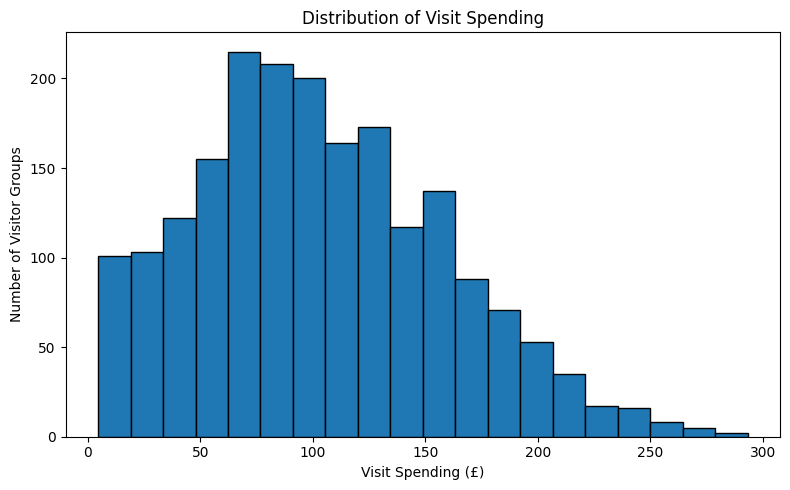

In [10]:
# Create a folder for figures that may later be used in the report.
output_folder = "coursework_outputs"
os.makedirs(output_folder, exist_ok=True)

# Print a short summary of the target variable.
print("Visit spending summary:")
print(cleaned_data["VisitSpending"].describe().round(2))

# Plot the distribution of visitor spending.
plt.figure(figsize=(8, 5))
plt.hist(cleaned_data["VisitSpending"], bins=20, edgecolor="black")
plt.title("Distribution of Visit Spending")
plt.xlabel("Visit Spending (£)")
plt.ylabel("Number of Visitor Groups")
plt.tight_layout()

# Save a high-quality copy for possible use in the report.
plt.savefig(
    os.path.join(output_folder, "visit_spending_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Numerical relationships with visit spending

Correlation measures the direction and strength of a linear relationship. Values closer to 1 show a stronger positive relationship, while values closer to -1 show a stronger negative relationship. Correlation does not prove that one variable causes another.

Correlation with VisitSpending:
Member               -0.357
WeekendVisit          0.030
AdvanceBooking        0.031
SpecialEvent          0.079
NumberOfChildren      0.320
VisitDurationHours    0.351
PartySize             0.446
MilesFromZoo          0.754
Name: VisitSpending, dtype: float64


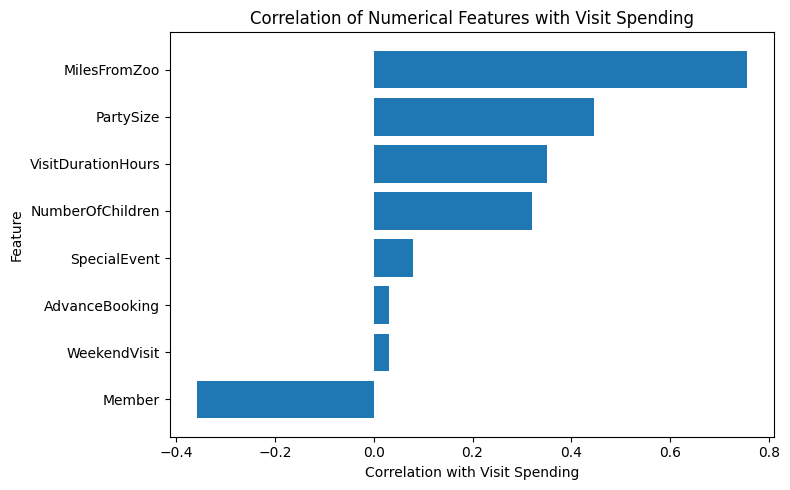

In [11]:
# Select only the numerical columns.
numerical_data = cleaned_data.select_dtypes(include=["int64", "float64"])

# Calculate each numerical variable's correlation with VisitSpending.
spending_correlations = numerical_data.corr()["VisitSpending"]

# Remove VisitSpending because its correlation with itself is always 1.
spending_correlations = spending_correlations.drop("VisitSpending")

# Sort the values so the chart is easier to read.
spending_correlations = spending_correlations.sort_values()

print("Correlation with VisitSpending:")
print(spending_correlations.round(3))

# Plot the correlations as a horizontal bar chart.
plt.figure(figsize=(8, 5))
plt.barh(spending_correlations.index, spending_correlations.values)
plt.title("Correlation of Numerical Features with Visit Spending")
plt.xlabel("Correlation with Visit Spending")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(
    os.path.join(output_folder, "spending_correlations.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Distance from the zoo and visit spending

`MilesFromZoo` has the strongest positive correlation with spending, so a scatter plot is used to inspect this relationship directly.

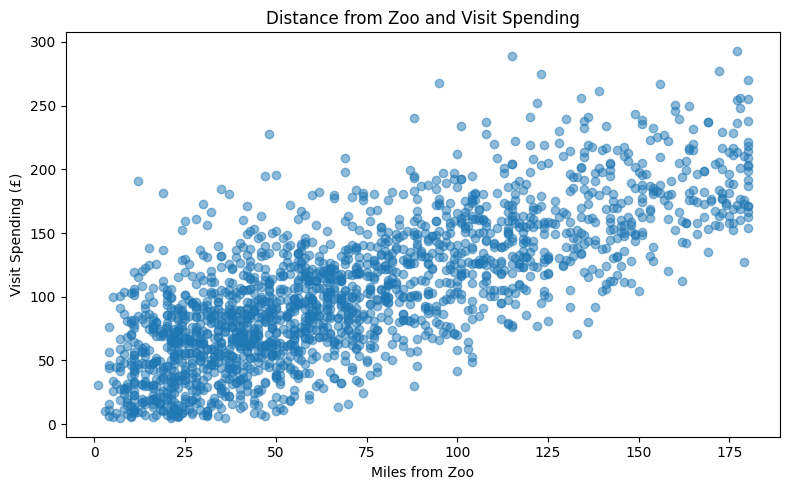

In [12]:
# Use rows where the distance value is available.
distance_data = cleaned_data.dropna(subset=["MilesFromZoo"])

# Plot distance against visit spending.
plt.figure(figsize=(8, 5))
plt.scatter(
    distance_data["MilesFromZoo"],
    distance_data["VisitSpending"],
    alpha=0.5
)
plt.title("Distance from Zoo and Visit Spending")
plt.xlabel("Miles from Zoo")
plt.ylabel("Visit Spending (£)")
plt.tight_layout()
plt.savefig(
    os.path.join(output_folder, "distance_and_spending.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Average spending by party size

This chart checks whether larger visitor groups tend to spend more during their visit.

Average spending by party size:
PartySize
1      68.75
2      82.63
3      86.03
4      95.27
5     108.45
6     123.23
7     129.96
8     152.08
9     170.56
10    177.19
Name: VisitSpending, dtype: float64


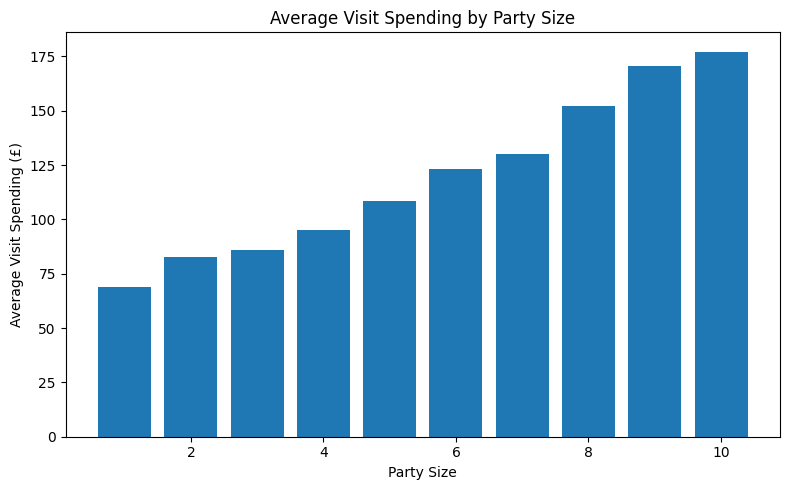

In [13]:
# Calculate the mean spending for each party size.
party_size_spending = cleaned_data.groupby("PartySize")["VisitSpending"].mean()

print("Average spending by party size:")
print(party_size_spending.round(2))

# Plot average spending for each party size.
plt.figure(figsize=(8, 5))
plt.bar(party_size_spending.index, party_size_spending.values)
plt.title("Average Visit Spending by Party Size")
plt.xlabel("Party Size")
plt.ylabel("Average Visit Spending (£)")
plt.tight_layout()
plt.savefig(
    os.path.join(output_folder, "spending_by_party_size.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Average spending by season

Season is categorical, so average spending is compared using a bar chart rather than a scatter plot.

Average spending by season:
Season
Autumn     98.71
Spring    102.37
Summer    111.53
Winter     97.94
Name: VisitSpending, dtype: float64


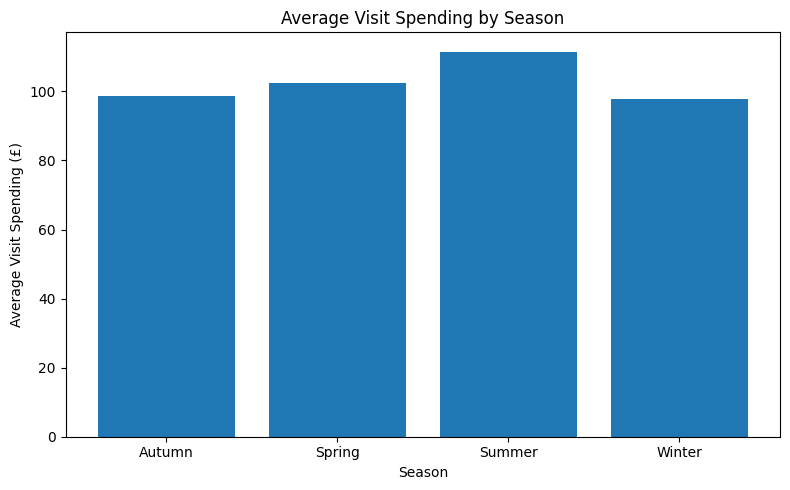

In [14]:
# Calculate average spending for each season.
season_spending = cleaned_data.groupby("Season")["VisitSpending"].mean()

print("Average spending by season:")
print(season_spending.round(2))

# Plot the average spending for each season.
plt.figure(figsize=(8, 5))
plt.bar(season_spending.index, season_spending.values)
plt.title("Average Visit Spending by Season")
plt.xlabel("Season")
plt.ylabel("Average Visit Spending (£)")
plt.tight_layout()
plt.savefig(
    os.path.join(output_folder, "spending_by_season.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Average spending by membership status

The `Member` column uses `0` for non-members and `1` for members. This chart compares the average spending of the two groups.

Average spending by membership status:
Member
0    126.20
1     86.55
Name: VisitSpending, dtype: float64


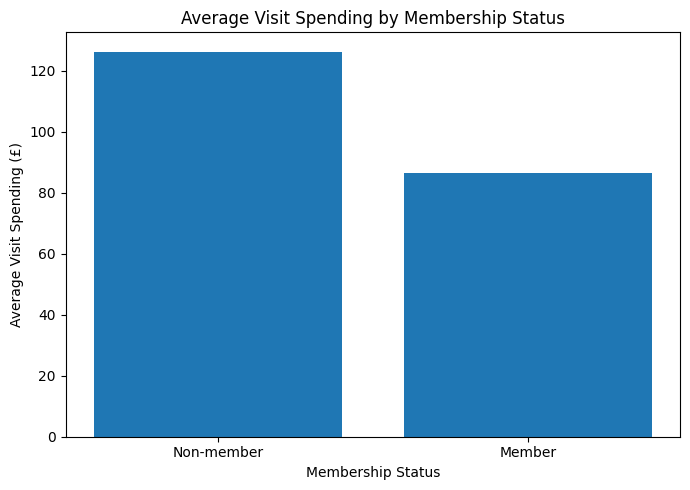

In [15]:
# Calculate average spending for non-members and members.
member_spending = cleaned_data.groupby("Member")["VisitSpending"].mean()

print("Average spending by membership status:")
print(member_spending.round(2))

# Use clear labels instead of 0 and 1 on the chart.
member_labels = ["Non-member", "Member"]

plt.figure(figsize=(7, 5))
plt.bar(member_labels, member_spending.values)
plt.title("Average Visit Spending by Membership Status")
plt.xlabel("Membership Status")
plt.ylabel("Average Visit Spending (£)")
plt.tight_layout()
plt.savefig(
    os.path.join(output_folder, "spending_by_membership.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Initial EDA findings

- After duplicate removal, the analysis uses **1,990 visitor records**.
- Visit spending ranges from **£4.59 to £293.11**, with a mean of approximately **£103.62** and a median of approximately **£98.10**.
- `MilesFromZoo` has the strongest positive linear relationship with spending, with a correlation of about **0.754**.
- Larger parties generally spend more, although there is still variation within each party size.
- Average spending is highest in **Summer** and lowest in **Winter** in this dataset.
- Non-members spend more on average than members. This may reflect membership discounts or other differences between the groups, but the chart alone cannot establish the cause.
- These patterns support using both numerical and categorical variables in the regression models.

## A4. Define the input features and target

The model will predict `VisitSpending`. This column becomes the target variable (`y`), while the remaining ten columns become the input features (`X`).

In [16]:
# Store the name of the value that the models will predict.
target_column = "VisitSpending"

# X contains the visitor details used to make predictions.
X = cleaned_data.drop(columns=[target_column])

# y contains the actual spending values that the models must learn to predict.
y = cleaned_data[target_column]

# Keep clear lists of numerical and categorical features.
# These lists will be used when missing values are filled and categories are encoded.
numerical_features = [
    "PartySize",
    "MilesFromZoo",
    "Member",
    "NumberOfChildren",
    "VisitDurationHours",
    "WeekendVisit",
    "SpecialEvent",
    "AdvanceBooking"
]

categorical_features = [
    "Season",
    "WeatherCondition"
]

print("Number of input features:", X.shape[1])
print("Number of target values:", y.shape[0])
print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)

Number of input features: 10
Number of target values: 1990

Numerical features: ['PartySize', 'MilesFromZoo', 'Member', 'NumberOfChildren', 'VisitDurationHours', 'WeekendVisit', 'SpecialEvent', 'AdvanceBooking']
Categorical features: ['Season', 'WeatherCondition']


## A5. Split and prepare the training and testing data

The data is split before missing values are filled. The replacement values are calculated from the training set and then applied to both sets, so the test data remains independent. An 80/20 split is used: 80% for learning and 20% for final evaluation.

In [17]:
# Split the data into training and testing sets.
# random_state keeps the split the same each time the notebook is run.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_SEED
)

# Create copies so the following changes do not affect the original X data.
X_train = X_train.copy()
X_test = X_test.copy()

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

# Fill missing numerical values with the median from the training set.
# The median is suitable because it is less affected by unusually high or low values.
print("\nNumerical values used to fill missing data:")

for column in numerical_features:
    training_median = X_train[column].median()
    X_train[column] = X_train[column].fillna(training_median)
    X_test[column] = X_test[column].fillna(training_median)
    print(column, "median =", round(training_median, 2))

# Fill missing categorical values with the most common training category.
print("\nCategorical values used to fill missing data:")

for column in categorical_features:
    most_common_value = X_train[column].mode()[0]
    X_train[column] = X_train[column].fillna(most_common_value)
    X_test[column] = X_test[column].fillna(most_common_value)
    print(column, "most common value =", most_common_value)

# Convert text categories into separate 0/1 columns.
# drop_first removes one reference category from each feature to avoid repeated information.
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

# Make sure the test set has exactly the same columns and order as the training set.
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Final checks before modelling.
print("\nMissing values in prepared training data:", X_train_encoded.isnull().sum().sum())
print("Missing values in prepared testing data:", X_test_encoded.isnull().sum().sum())
print("Prepared training shape:", X_train_encoded.shape)
print("Prepared testing shape:", X_test_encoded.shape)

print("\nPrepared feature columns:")
for column in X_train_encoded.columns:
    print("-", column)

Training rows: 1592
Testing rows: 398

Numerical values used to fill missing data:
PartySize median = 4.0
MilesFromZoo median = 61.0
Member median = 1.0
NumberOfChildren median = 1.0
VisitDurationHours median = 3.45
WeekendVisit median = 1.0
SpecialEvent median = 0.0
AdvanceBooking median = 1.0

Categorical values used to fill missing data:
Season most common value = Summer
WeatherCondition most common value = Sunny

Missing values in prepared training data: 0
Missing values in prepared testing data: 0
Prepared training shape: (1592, 13)
Prepared testing shape: (398, 13)

Prepared feature columns:
- PartySize
- MilesFromZoo
- Member
- NumberOfChildren
- VisitDurationHours
- WeekendVisit
- SpecialEvent
- AdvanceBooking
- Season_Spring
- Season_Summer
- Season_Winter
- WeatherCondition_Rainy
- WeatherCondition_Sunny


### Data preparation summary

- **10 exact duplicate rows** were removed, leaving **1,990 records**.
- The target variable had no missing values.
- Numerical missing values were replaced using medians calculated from the training set.
- Categorical missing values were replaced using the most common training category.
- `Season` and `WeatherCondition` were converted into numerical indicator columns.
- The final split contains **1,592 training rows** and **398 testing rows**.
- All preprocessing decisions were based on the training set to reduce data leakage.

## A6. Train regression models

Two regression models are trained so their performance can be compared fairly in the next section.

- **Linear Regression** is used as a simple baseline. It assumes that the target changes through a linear combination of the input features.
- **Random Forest Regressor** is used as a more flexible model. It combines many decision trees and can learn non-linear relationships and feature interactions.

Both models use the same prepared training data. The test data is not used during training.


In [18]:
# Import the two regression models used in this project.
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


# Create the Linear Regression model.
# This provides a simple baseline that the more flexible model can be compared against.
linear_regression_model = LinearRegression()

# Train the model using the prepared training features and known spending values.
linear_regression_model.fit(X_train_encoded, y_train)

print("Linear Regression model trained successfully.")


# Create the Random Forest model.
# n_estimators=100 means that the model combines predictions from 100 decision trees.
# random_state keeps the model results reproducible.
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_SEED
)

# Train the Random Forest using the same prepared training data.
random_forest_model.fit(X_train_encoded, y_train)

print("Random Forest model trained successfully.")
print("Number of trees:", random_forest_model.n_estimators)


Linear Regression model trained successfully.


Random Forest model trained successfully.
Number of trees: 100


## A7. Evaluate and compare the regression models

The two trained models are tested on the same unseen test data. Their predictions are compared with the real `VisitSpending` values using two measures:

- **RMSE** shows the typical size of the prediction error in pounds. A lower RMSE is better.
- **R²** shows how much of the variation in spending is explained by the model. A value closer to 1 is better.

Actual-versus-predicted plots are also used to show how closely each model's predictions follow the real values.

Regression model comparison:
            Model     MSE   RMSE    R2
Linear Regression 527.016 22.957 0.833
    Random Forest 643.575 25.369 0.796

Selected regression model: Linear Regression
Selected model RMSE: £22.96
Selected model R²: 0.833


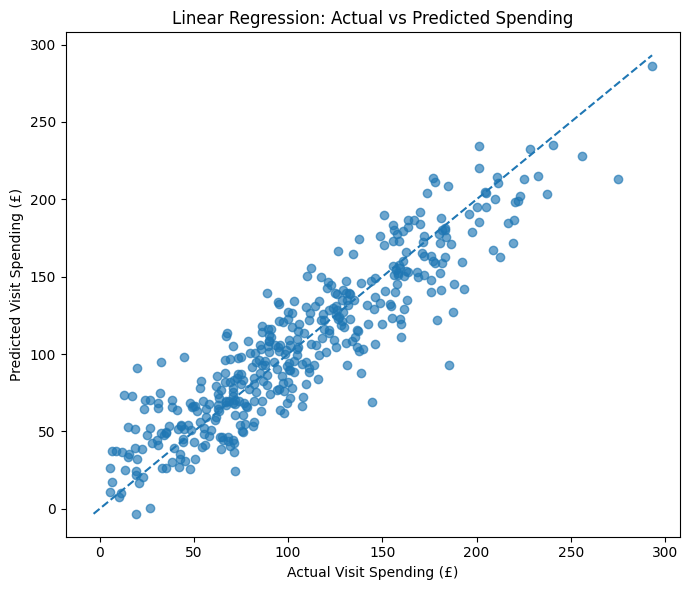

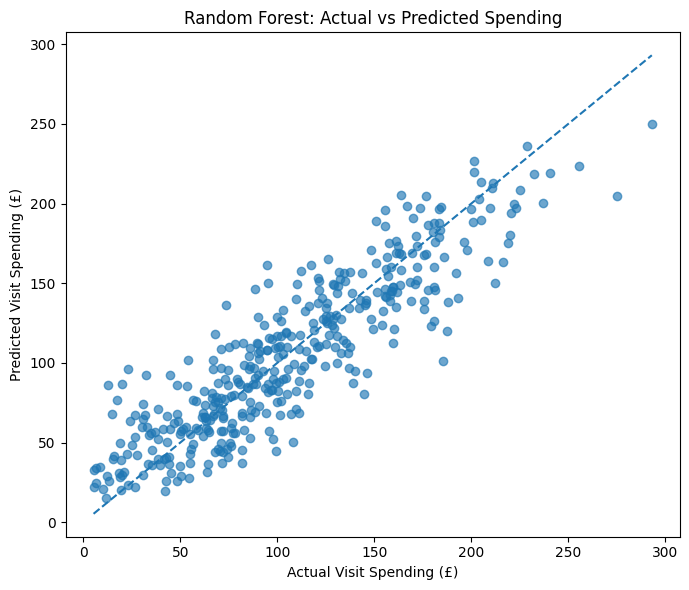

In [19]:
# Import the regression evaluation measures.
from sklearn.metrics import mean_squared_error, r2_score


# ---------------------------------------------------------
# Linear Regression evaluation
# ---------------------------------------------------------

# Use the trained Linear Regression model to predict the test data.
linear_predictions = linear_regression_model.predict(X_test_encoded)

# Calculate the mean squared error.
linear_mse = mean_squared_error(y_test, linear_predictions)

# Take the square root so the error is measured in pounds.
linear_rmse = np.sqrt(linear_mse)

# Calculate how much of the variation in spending is explained by the model.
linear_r2 = r2_score(y_test, linear_predictions)


# ---------------------------------------------------------
# Random Forest evaluation
# ---------------------------------------------------------

# Use the trained Random Forest model to predict the same test data.
random_forest_predictions = random_forest_model.predict(X_test_encoded)

# Calculate the mean squared error.
random_forest_mse = mean_squared_error(
    y_test,
    random_forest_predictions
)

# Convert the error into pounds.
random_forest_rmse = np.sqrt(random_forest_mse)

# Calculate the R² score.
random_forest_r2 = r2_score(
    y_test,
    random_forest_predictions
)


# ---------------------------------------------------------
# Compare the model results
# ---------------------------------------------------------

# Put the scores into a clear table.
regression_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MSE": [linear_mse, random_forest_mse],
    "RMSE": [linear_rmse, random_forest_rmse],
    "R2": [linear_r2, random_forest_r2]
})

print("Regression model comparison:")
print(regression_results.round(3).to_string(index=False))


# Select the model with the lower RMSE.
if linear_rmse < random_forest_rmse:
    best_regression_model = linear_regression_model
    best_regression_name = "Linear Regression"
    best_regression_predictions = linear_predictions
    best_regression_rmse = linear_rmse
    best_regression_r2 = linear_r2
else:
    best_regression_model = random_forest_model
    best_regression_name = "Random Forest"
    best_regression_predictions = random_forest_predictions
    best_regression_rmse = random_forest_rmse
    best_regression_r2 = random_forest_r2

print()
print("Selected regression model:", best_regression_name)
print("Selected model RMSE: £" + str(round(best_regression_rmse, 2)))
print("Selected model R²:", round(best_regression_r2, 3))


# ---------------------------------------------------------
# Linear Regression: actual values against predictions
# ---------------------------------------------------------

# Find the chart limits so the diagonal reference line covers the full plot.
linear_minimum = min(y_test.min(), linear_predictions.min())
linear_maximum = max(y_test.max(), linear_predictions.max())

plt.figure(figsize=(7, 6))
plt.scatter(y_test, linear_predictions, alpha=0.65)
plt.plot(
    [linear_minimum, linear_maximum],
    [linear_minimum, linear_maximum],
    linestyle="--"
)
plt.title("Linear Regression: Actual vs Predicted Spending")
plt.xlabel("Actual Visit Spending (£)")
plt.ylabel("Predicted Visit Spending (£)")
plt.tight_layout()

plt.savefig(
    os.path.join(
        output_folder,
        "linear_regression_actual_vs_predicted.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ---------------------------------------------------------
# Random Forest: actual values against predictions
# ---------------------------------------------------------

# Find the chart limits for the Random Forest plot.
forest_minimum = min(y_test.min(), random_forest_predictions.min())
forest_maximum = max(y_test.max(), random_forest_predictions.max())

plt.figure(figsize=(7, 6))
plt.scatter(y_test, random_forest_predictions, alpha=0.65)
plt.plot(
    [forest_minimum, forest_maximum],
    [forest_minimum, forest_maximum],
    linestyle="--"
)
plt.title("Random Forest: Actual vs Predicted Spending")
plt.xlabel("Actual Visit Spending (£)")
plt.ylabel("Predicted Visit Spending (£)")
plt.tight_layout()

plt.savefig(
    os.path.join(
        output_folder,
        "random_forest_actual_vs_predicted.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Regression evaluation findings

- **Linear Regression** achieved an RMSE of approximately **£22.96** and an R² score of **0.833**.
- **Random Forest** achieved an RMSE of approximately **£25.37** and an R² score of **0.796**.
- Linear Regression performed better because it produced the lower prediction error and the higher R² score on unseen test data.
- The selected model's predictions are typically about **£22.96** away from the real spending value.
- An R² of **0.833** means that the model explains about **83.3%** of the variation in visitor spending in this test set.
- The actual-versus-predicted charts show that both models capture the general spending pattern, although some points remain away from the ideal diagonal line.

These results apply to this particular dataset and test split. They do not guarantee the same accuracy for every future zoo visitor group.

## A8. Feature importance and Part A conclusion


Random Forest feature importance:
               Feature  Importance
          MilesFromZoo       0.612
             PartySize       0.212
    VisitDurationHours       0.070
                Member       0.022
      NumberOfChildren       0.017
         Season_Summer       0.010
WeatherCondition_Sunny       0.009
          WeekendVisit       0.009
          SpecialEvent       0.009
        AdvanceBooking       0.008
WeatherCondition_Rainy       0.008
         Season_Spring       0.007
         Season_Winter       0.006


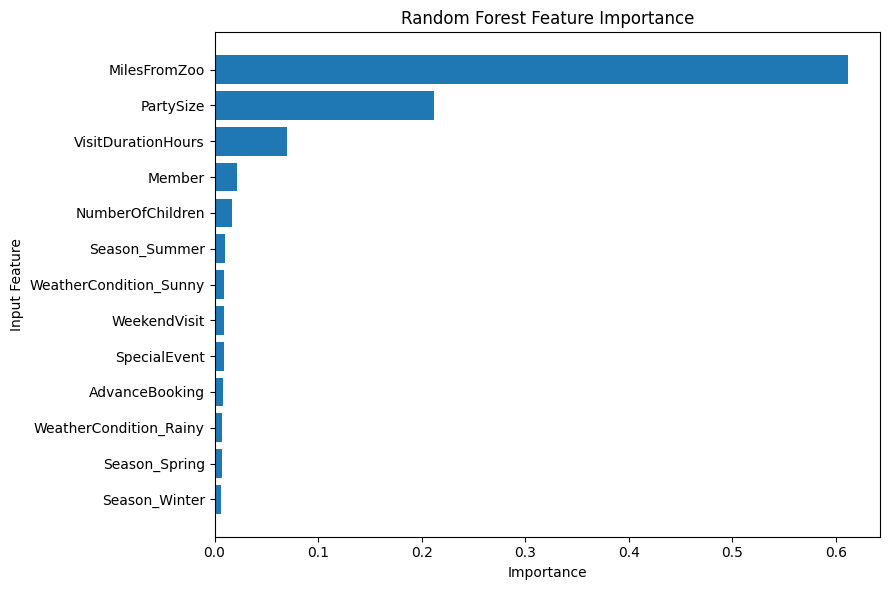

In [20]:
# ---------------------------------------------------------
# Random Forest feature importance
# ---------------------------------------------------------

# Random Forest records how much each input feature helped its decision trees.
# A larger value means the feature was used more when making predictions.
feature_importance = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": random_forest_model.feature_importances_
})

# Sort the features from most important to least important.
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest feature importance:")
print(feature_importance.round(3).to_string(index=False))


# Plot the feature importance values.
plt.figure(figsize=(9, 6))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

# Put the most important feature at the top of the chart.
plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Input Feature")
plt.tight_layout()

# Save a high-quality copy for possible use in the report.
plt.savefig(
    os.path.join(
        output_folder,
        "regression_feature_importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Part A conclusion

The regression task compared a simple Linear Regression model with a more flexible Random Forest Regressor. Linear Regression was selected because it achieved the lower test RMSE (**£22.96**) and the higher R² score (**0.833**). The Random Forest achieved an RMSE of **£25.37** and an R² of **0.796**. These results suggest that the main spending patterns in this dataset can be represented well by a linear model, despite the Random Forest being able to model more complex relationships.

The Random Forest feature-importance analysis identified `MilesFromZoo` as the strongest input, with an importance of approximately **0.612**. `PartySize` was the second most important feature at approximately **0.212**, followed by `VisitDurationHours` at approximately **0.070**. The remaining features had much smaller importance values. These values show which inputs the Random Forest used most, but they do not prove that any feature causes higher spending.

Important limitations are:

- missing numerical values were replaced with training-set medians and missing categorical values with the most common training category;
- the results are based on one train/test split;
- the dataset represents historical visitor patterns and may not capture every future pricing or visitor behaviour change;
- `VisitDurationHours` is described as time spent in the zoo, although the scenario treats it as information available before a visit. This difference could limit how realistically the model can be used for an advance estimate.

Part A now meets the main regression requirements: data exploration, preparation, two trained models, test-set evaluation, model comparison, a selected model, visual results and feature-importance analysis.


# Part B — Animal Image Classification

The aim of Part B is to classify animal photographs into one of the ten provided animal categories.


## B1. Inspect the image dataset


In [21]:
# Image dataset inspection code will be added here.


## B2. Prepare and split the image data


In [22]:
# Image resizing, normalisation and splitting code will be added here.


## B3. Baseline CNN


In [23]:
# Baseline CNN code will be added here.


## B4. Improved CNN


In [24]:
# Improved CNN code will be added here.


## B5. Evaluate and compare the image models


In [25]:
# Accuracy, precision, recall, F1-score, confusion matrix and learning curves will be added here.


## B6. Predict a previously unseen animal image


In [ ]:
# Unseen image prediction code will be added here.


## B7. Part B conclusion and limitations


In [ ]:
# Final Part B discussion will be added here.


# Final Project Conclusion

This section will summarise the selected regression model, selected image classifier, main results, limitations and possible improvements.
